# Reconstructing the 1850s seabed at the Periyar mouth from Admiralty soundings

## 1. Introduction and research question

The *Periplus* places Muziris "twenty stadia up the river" from the sea, and the
water-depth question for the thesis is whether a ship of a given draught could
have got in. There is no measured modern bathymetry at the Periyar entrances, so
the earliest dense depth survey is the one we have: Lieutenant Selby's survey of
1851–53, engraved as Admiralty sheet 749 and first published in 1857.

This notebook turns the soundings on that sheet into a continuous seabed surface
with uncertainty, and compares two spatial models:

* **Model A**, a stationary Matérn Gaussian field, in which correlation depends
  only on straight-line distance;
* **Model B**, the barrier model of Bakka et al. (2019), in which correlation
  cannot pass through land, so a sand spit separates the water on either side.

The pilot region is the Kodungallur (Azhikode) mouth of the Periyar, the
"Kranganur" entrance and the Pallipur river on the chart, which is the
approach to the Pattanam candidate for Muziris.

Scope. This is a reconstruction of the seabed **as surveyed in 1851–53**. Nothing
here is a statement about the first century AD; that is a later step that needs a
sea-level curve and a sediment budget. A short final section also fits the eleven
soundings on the Dutch-French chart of about 1700.

How it runs. Preprocessing and plotting are in Python. The models are fitted in
R with R-INLA through `rpy2` (`%%R` cells). The whole notebook runs in about
three to four minutes. The transcription itself was done once by hand and is
read from `scripts/transcription_1857.py`.

In [1]:
import json, sys, pathlib, os
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from PIL import Image
from shapely.geometry import Polygon, LineString, Point, box
from shapely.ops import unary_union
from pyproj import Transformer

os.environ.setdefault("R_HOME", "/Library/Frameworks/R.framework/Resources")
os.environ.setdefault("RPY2_CFFI_MODE", "ABI")              # the wheel's API mode expects R 4.6
Image.MAX_IMAGE_PIXELS = None
ROOT = pathlib.Path.cwd().resolve().parents[1]           # notebook lives in quantitative/coastline
sys.path.insert(0, str(ROOT / "quantitative" / "coastline" / "scripts"))
from detect_soundings import WINDOW
from barriers_1857 import BARRIERS

DATA = ROOT / "quantitative" / "coastline" / "data"
PILOT = DATA / "pilot_1857"; PILOT.mkdir(exist_ok=True)
PILOT_DIR = str(PILOT)                                  # for passing to R
FIGS = ROOT / "quantitative" / "coastline" / "figures"; FIGS.mkdir(exist_ok=True)
CHART = Image.open(ROOT.parent / "library" / "charts" / "malabar-749-1857.jpg")
FATHOM = 1.8288
rng = np.random.default_rng(749)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
%load_ext rpy2.ipython

In [3]:
%%R
.libPaths(c(path.expand("~/Library/R/arm64/4.5/library"), .libPaths()))
suppressMessages({library(INLA); library(fmesher); library(sf)})
inla.setOption(num.threads = "4:1")
set.seed(749)
cat("INLA", as.character(packageVersion("INLA")), "\n")

INLA

25.10.19

## 2. Data sources and preparation

**The chart.** The scan is of Admiralty sheet 749, *West Coast of India, Malabar
Coast, from 11°2′ to 9°50′ north latitude, by Lieut. W. B. Selby I.N., 1851–3*,
published by John Walker on 10 October 1857. The copy is the **1914 edition**: the
imprint reads "New Editions June 1888, 9th Oct. 1914", and the magnetic note is
dated 1914. The soundings are Selby's, but an edition can carry later corrections,
and nothing on the sheet marks which soundings, if any, were changed. This is a
standing caveat on everything below.

**Units.** The title block states *Soundings in Fathoms*. Fractions are printed in
quarters (¼, ½, ¾). One fathom is 1.8288 m.

**Datum.** The sheet does **not** state a sounding datum. It gives the tide at
Cochin: high water at full and change XIh 26m, "Springs rise 3 feet, Neaps rise
2¼ feet". Indian Navy surveys of this period normally reduced soundings to low
water of spring tides, and that is assumed here. It is an assumption, so the
absolute depths carry an unknown offset of up to the spring rise, 0.91 m, common
to every sounding.

**Coordinates.** The sheet is georeferenced from its own printed graticule
(`quantitative/src/charts/sheets.py`): the latitude ticks fit to 0.007 arcmin, and
the opposite neatline is recovered to within 75 m. Longitudes on the sheet depend
on Kolaba Observatory at 72°48′47″E. Positions are projected to UTM zone 43N and
used in kilometres.

In [4]:
g = json.loads((ROOT / "data/processed/charts/admiralty_georef.json").read_text())["BA749"]
to_utm = Transformer.from_crs("EPSG:4326", "EPSG:32643", always_xy=True)

def win_to_km(x, y):
    # window pixel -> chart pixel -> lon/lat from the sheet's graticule -> UTM 43N, km
    cx, cy = np.asarray(x, float) + WINDOW["x0"], np.asarray(y, float) + WINDOW["y0"]
    lat = g["lat_a"] * cy + g["lat_b"]
    lon = g["lon_anchor_deg"] + (cx - g["lon_anchor_px"]) / g["px_per_arcmin_lon"] / 60
    e, n = to_utm.transform(lon, lat)
    return np.asarray(e) / 1000, np.asarray(n) / 1000

print("pilot window, chart pixels:", WINDOW)
print(f"1 chart pixel ≈ {1852 / g['px_per_arcmin_lat']:.1f} m")

pilot window, chart pixels: {'x0': 5600, 'y0': 7600, 'x1': 7300, 'y1': 9300}
1 chart pixel ≈ 12.2 m


### Transcription workflow

Automatic reading of engraved italic numerals with stacked fractions is not
reliable, so the soundings were transcribed by eye in three steps:

1. `detect_soundings.py` finds candidate glyph clusters in the window (ink mass and
   size thresholds, which drop the dash-dot depth contours) and draws numbered
   boxes on sixteen 2× tiles.
2. Each box was read and entered in `transcription_1857.py` with a status: `ok`,
   `unsure` (legible but could be misread, or a lone fraction such as ½ that might
   not be a sounding), `edge` (cut by the window), `not` (a palm, a letter, a bank
   line), or `split` (two numbers merged into one box, re-entered separately).
   Numbers the detector missed were added by hand with their pixel position.
3. A second pass re-read every value against its own crop on contact sheets
   (`data/soundings_1857/check/`). That pass changed no values; it upgraded five
   `unsure` readings to `ok`, dropped one ambiguous half-fathom, and corrected one
   hand-placed position.

The detector systematically missed isolated single digits, mostly 7s, which is why
59 of the soundings were added by hand. Hand-added positions are good to about
±5 chart pixels (≈60 m).

In [5]:
s_all = pd.read_csv(DATA / "soundings_1857" / "soundings_1857.csv")
print(s_all.status.value_counts().to_string(), "\n")
print(pd.crosstab(s_all.source, s_all.status))
s = s_all[s_all.status.isin(["ok", "unsure"])].copy()
s["x_km"], s["y_km"] = win_to_km(s.win_x, s.win_y)
s["depth_m"] = s.fathoms * FATHOM

status
ok        403
not        35
unsure     25
edge        4
split       4
drop        1 

status         drop  edge  not   ok  split  unsure
source                                            
added by hand     0     0    0   45      0      13
detector          1     4   35  358      4      12


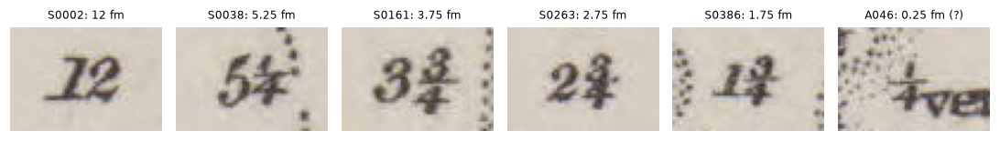

In [6]:
# what the transcription looks like against the chart
fig, axes = plt.subplots(1, 6, figsize=(10, 1.6))
for ax, sid in zip(axes, ["S0002", "S0038", "S0161", "S0263", "S0386", "A046"]):
    r = s_all.set_index("id").loc[sid]
    cx, cy = int(r.chart_x), int(r.chart_y)
    ax.imshow(CHART.crop((cx - 32, cy - 22, cx + 32, cy + 22)))
    ax.set_title(f"{sid}: {r.fathoms:g} fm" + (" (?)" if r.status == "unsure" else ""), fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

### Measurement uncertainty

Each sounding carries several error terms. None of them is estimated from the
chart alone, so they are listed here and the model estimates a single Gaussian
observation noise σ<sub>ε</sub>, which should come out at least as large as these
combined.

| Term | Size | Note |
|---|---|---|
| Rounding to the printed quarter fathom | ±0.23 m | half of ¼ fathom |
| Lead-line reading in swell, stretch of line | ~0.3 m | typical of the period, not measured |
| Tide reduction | up to 0.91 m | spring rise on the sheet; systematic if the datum is wrong |
| Position of a hand-added sounding | ±60 m | matters only on steep slopes |
| Copying and engraving between 1853 and 1914 | unknown | |

The project's earlier error budget for the Dutch chart (`soundings_error.py`) put
the random part at about 0.58 m; the fitted noise below is about 0.66 m.

### Land barriers and the model domain

The sheet shows land as stipple and the coast as a heavy line, but automatic
segmentation of the stipple missed the palm-fringed coastal strip and the narrow
spits, which are the features that matter for a barrier model. So the barriers were
digitised by hand on a 50-pixel grid (`barriers_1857.py`; ±10 px ≈ 120 m). Everything
east of the coast is treated as land except the open mouth, because the
backwaters were not sounded and are outside this model. The figure checks the
polygons against the chart.

428 soundings: 74 in the Pallipur channel, 63 within 1 km of land, 0 with a spit between them and the open sea
domain 17.6 x 20.6 km, water 288 km²


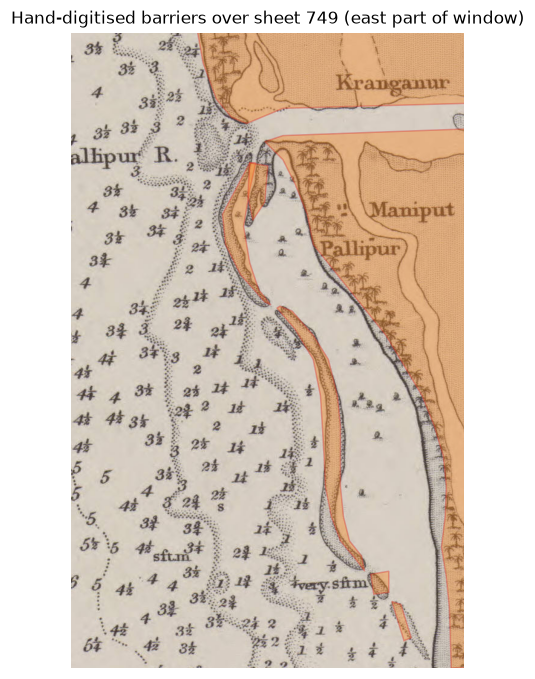

In [7]:
land = unary_union([Polygon(np.column_stack(win_to_km(*zip(*p)))) for p in BARRIERS.values()]).buffer(0)
x0, y0 = win_to_km(0, 1700); x1, y1 = win_to_km(1450, 0)
domain = box(float(x0), float(y0), float(x1), float(y1))
land = land.intersection(domain)
coast = land.boundary
s = s[[domain.contains(Point(a, b)) for a, b in zip(s.x_km, s.y_km)]].copy()
assert not any(land.contains(Point(a, b)) for a, b in zip(s.x_km, s.y_km))

s["dist_km"] = [coast.distance(Point(a, b)) for a, b in zip(s.x_km, s.y_km)]
# the sounded Pallipur channel: south of the mouth, between the dotted shoal line and the spits
s["channel"] = (s.win_x > 1000) & (s.win_y > 850)
behind = [LineString([(a, b), (a - 3, b)]).intersects(land) for a, b in zip(s.x_km, s.y_km)]
print(f"{len(s)} soundings: {s.channel.sum()} in the Pallipur channel, {(s.dist_km < 1).sum()} within 1 km of land, "
      f"{sum(behind)} with a spit between them and the open sea")
print(f"domain {domain.bounds[2]-domain.bounds[0]:.1f} x {domain.bounds[3]-domain.bounds[1]:.1f} km, water {domain.difference(land).area:.0f} km²")

win = CHART.crop((WINDOW["x0"] + 800, WINDOW["y0"] + 650, WINDOW["x0"] + 1450, WINDOW["y0"] + 1700))
fig, ax = plt.subplots(figsize=(5, 7.5))
ax.imshow(win)
for p in BARRIERS.values():
    xy = np.array(p, float) - [800, 650]
    ax.fill(*xy.T, color="tab:orange", alpha=.35, lw=1, ec="tab:red")
ax.set_xlim(0, 650); ax.set_ylim(1050, 0); ax.axis("off")
ax.set_title("Hand-digitised barriers over sheet 749 (east part of window)")
plt.show()

## 3. Exploratory data analysis

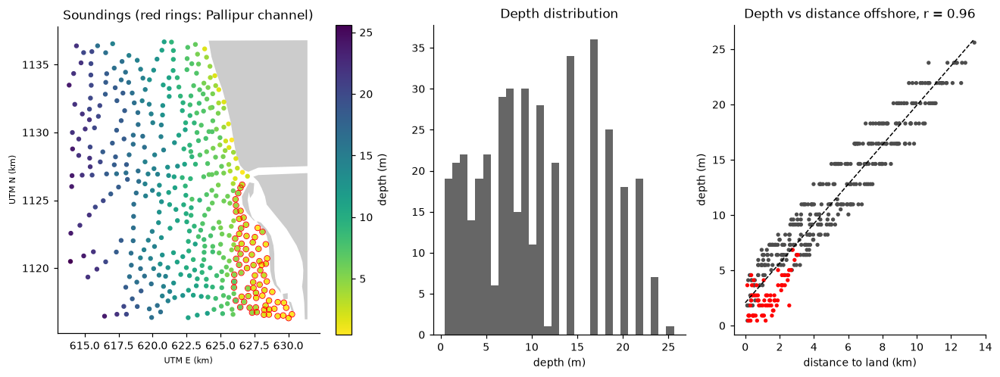

nearest-neighbour spacing: median 546 m, 90th pct 763 m


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4.6), gridspec_kw=dict(width_ratios=[1.3, 1, 1]))
gpd.GeoSeries([land]).plot(ax=ax[0], color="0.8")
sc = ax[0].scatter(s.x_km, s.y_km, c=s.depth_m, s=10, cmap="viridis_r")
ax[0].scatter(s.x_km[s.channel], s.y_km[s.channel], s=24, facecolors="none", edgecolors="r", lw=.6)
plt.colorbar(sc, ax=ax[0], label="depth (m)"); ax[0].set_aspect("equal")
ax[0].set_title("Soundings (red rings: Pallipur channel)"); ax[0].set_xlabel("UTM E (km)"); ax[0].set_ylabel("UTM N (km)")
ax[1].hist(s.depth_m, bins=30, color="0.4"); ax[1].set_xlabel("depth (m)"); ax[1].set_title("Depth distribution")
ax[2].scatter(s.dist_km, s.depth_m, s=6, c=np.where(s.channel, "r", "0.3"))
b = np.polyfit(s.dist_km, s.depth_m, 1)
xx = np.linspace(0, s.dist_km.max(), 10); ax[2].plot(xx, np.polyval(b, xx), "k--", lw=1)
ax[2].set_xlabel("distance to land (km)"); ax[2].set_ylabel("depth (m)")
ax[2].set_title(f"Depth vs distance offshore, r = {np.corrcoef(s.dist_km, s.depth_m)[0,1]:.2f}")
plt.tight_layout(); plt.show()

from scipy.spatial import cKDTree
d_nn, _ = cKDTree(s[["x_km", "y_km"]]).query(s[["x_km", "y_km"]], k=2)
print(f"nearest-neighbour spacing: median {np.median(d_nn[:,1])*1000:.0f} m, 90th pct {np.percentile(d_nn[:,1],90)*1000:.0f} m")

Depth is close to linear in distance from land (r ≈ 0.96), so distance offshore is
used as the mean function. The soundings are dense along the coast and sparse
offshore, which is how a lead-line survey is run. One fact about the survey shapes
everything below: **Selby sounded the channel seaward of the spits, not the water
behind them.** No sounding has a spit between it and the open sea. The barrier
model therefore has almost no data on the far side of a barrier to learn from.

## 4. Statistical framework

Let $D(s)$ be water depth (metres, positive down) at location $s=(x,y)$. Each
sounding is

$$y_i = D(s_i) + \varepsilon_i,\qquad \varepsilon_i \sim N(0,\sigma_\varepsilon^2),$$

$$D(s) = \beta_0 + \beta_1\, d(s) + u(s),$$

where $d(s)$ is distance to land and $u$ is a zero-mean Gaussian field.

**Model A.** $u$ is Matérn with smoothness $\nu = 1$, range $\rho$ and marginal sd
$\sigma_u$. Following Lindgren, Rue and Lindström (2011) it is represented as the
solution of the SPDE $(\kappa^2 - \Delta)\,u = \mathcal W$ on a triangular mesh, which
gives a sparse precision matrix and makes the fit fast. The covariance depends
only on straight-line distance, so it passes through land.

**Model B.** Bakka et al. (2019) give the field a different range in the land
triangles of the mesh: the physical range $\rho$ in water and $r\rho$ on land, with
$r = 0.1$. Correlation then decays almost to nothing across a spit and has to go
round it through water. This is defined through the SPDE, so the precision matrix is
a valid GMRF, and the covariance is positive definite by construction. It is
*not* the same as plugging a shortest-water-path distance into a Matérn formula,
which is not guaranteed to be positive definite.

**Priors.** These are penalised-complexity (PC) priors:

* range: $P(\rho < 0.5\text{ km}) = 0.1$, because the soundings are 300–700 m apart and a
  field varying on a shorter scale could not be learnt from them;
* field sd: $P(\sigma_u > 5\text{ m}) = 0.1$;
* noise sd: $P(\sigma_\varepsilon > 0.5\text{ m}) = 0.5$, centred on the error budget above;
* $\beta_0,\beta_1$: INLA's default vague Gaussians.

**Inference.** Hyperparameters are estimated with INLA's empirical-Bayes strategy
(`int.strategy = "eb"`), and the latent field is then exactly Gaussian given them.
Joint posterior samples of the whole surface come from `inla.posterior.sample`.
The barrier model runs through INLA's original `rgeneric` implementation
(`enable.INLAspacetime = FALSE`), because the faster compiled version needs a newer
INLA than R 4.5 allows. It is the same model, only slower.

In [9]:
s[["id", "x_km", "y_km", "depth_m", "dist_km", "channel", "status"]].to_csv(PILOT / "soundings.csv", index=False)
gpd.GeoSeries([land]).to_file(PILOT / "land.geojson", driver="GeoJSON")
gpd.GeoSeries([domain]).to_file(PILOT / "domain.geojson", driver="GeoJSON")

# prediction grid at 150 m
step = 0.15
gx, gy = np.meshgrid(np.arange(domain.bounds[0] + step/2, domain.bounds[2], step),
                     np.arange(domain.bounds[1] + step/2, domain.bounds[3], step))
pts = gpd.points_from_xy(gx.ravel(), gy.ravel())
is_water = ~gpd.GeoSeries(pts).within(land).values
grid = pd.DataFrame(dict(x_km=gx.ravel(), y_km=gy.ravel(), water=is_water))
grid["dist_km"] = [coast.distance(p) if w else 0.0 for p, w in zip(pts, is_water)]
grid.assign(water=grid.water.astype(int)).to_csv(PILOT / "grid.csv", index=False)
print(grid.shape, "grid cells,", grid.water.sum(), "in water")

(16146, 4) grid cells, 12876 in water


/Users/vivek/Documents/Thesis/Code/.venv/lib/python3.13/site-packages/pyogrio/geopandas.py:948: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(
/Users/vivek/Documents/Thesis/Code/.venv/lib/python3.13/site-packages/pyogrio/geopandas.py:948: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(


## 5. Mesh

Both models share one mesh, so differences between them come from the barrier
alone. The inner edge length is 350 m, about the spacing of the inshore
soundings, and the outer extension of 2 km keeps the SPDE boundary effect away
from the data. A mesh triangle counts as barrier if its centroid lies on land.

In [10]:
%%R -i PILOT_DIR -o mesh_loc -o mesh_tv -o bar_tri
D <- paste0(PILOT_DIR, "/")
s    <- read.csv(paste0(D, "soundings.csv"))
grid <- read.csv(paste0(D, "grid.csv"))
land <- st_read(paste0(D, "land.geojson"), quiet = TRUE);   st_crs(land) <- NA
dom  <- st_read(paste0(D, "domain.geojson"), quiet = TRUE); st_crs(dom) <- NA

make_mesh <- function(max_edge) fm_mesh_2d_inla(boundary = dom, max.edge = c(max_edge, 2),
                                                cutoff = max_edge / 3.5, offset = c(0.3, 2))
barrier_triangles <- function(mesh) {
  cent <- st_centroid(fm_as_sfc(mesh)); st_crs(cent) <- NA
  which(st_intersects(cent, land, sparse = FALSE)[, 1])
}
mesh <- make_mesh(0.35)
bar_tri <- barrier_triangles(mesh)
mesh_loc <- mesh$loc[, 1:2]; mesh_tv <- mesh$graph$tv
cat(mesh$n, "mesh nodes,", nrow(mesh_tv), "triangles,", length(bar_tri), "of them barrier\n")

7810

mesh nodes,

15539

triangles,

3049

of them barrier


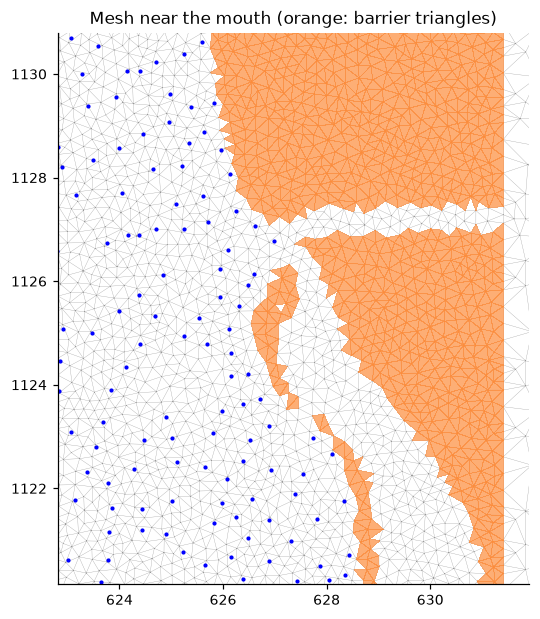

In [11]:
fig, ax = plt.subplots(figsize=(6, 6.5))
tv = np.asarray(mesh_tv, int) - 1; loc = np.asarray(mesh_loc)
bt = np.asarray(bar_tri, int) - 1
ax.triplot(loc[:, 0], loc[:, 1], tv, lw=.2, color="0.6")
ax.tripcolor(loc[:, 0], loc[:, 1], tv[bt], np.ones(len(bt)), cmap="Oranges", vmin=0, vmax=2, alpha=.7)
ax.scatter(s.x_km, s.y_km, s=3, c="b")
ax.set_xlim(domain.bounds[0] + 9, domain.bounds[2] + .5); ax.set_ylim(domain.bounds[1] + 4, domain.bounds[3] - 6)
ax.set_aspect("equal"); ax.set_title("Mesh near the mouth (orange: barrier triangles)")
plt.show()

## 6. Fitting the stationary (A) and barrier (B) models

In [12]:
%%R -o fixed_tab -o hyper_tab -o mlik
fit_model <- function(mesh, bar_tri, barrier, y = s$depth_m, range_fraction = 0.1, mode = NULL) {
  spde <- if (barrier) {
    suppressWarnings(inla.barrier.pcmatern(mesh, barrier.triangles = bar_tri, prior.range = c(0.5, 0.1),
                     prior.sigma = c(5, 0.1), range.fraction = range_fraction, enable.INLAspacetime = FALSE))
  } else inla.spde2.pcmatern(mesh, prior.range = c(0.5, 0.1), prior.sigma = c(5, 0.1))
  A <- fm_basis(mesh, loc = as.matrix(s[, c("x_km", "y_km")]))
  stk <- inla.stack(data = list(y = y), A = list(A, 1), tag = "est",
                    effects = list(field = 1:mesh$n, data.frame(b0 = 1, dist = s$dist_km)))
  suppressWarnings(inla(y ~ 0 + b0 + dist + f(field, model = spde), data = inla.stack.data(stk),
       control.predictor = list(A = inla.stack.A(stk), compute = TRUE),
       control.family = list(hyper = list(prec = list(prior = "pc.prec", param = c(0.5, 0.5)))),
       control.compute = list(config = TRUE),
       control.mode = if (is.null(mode)) list() else list(theta = mode, restart = TRUE),
       control.inla = list(int.strategy = "eb")))
}

t0 <- Sys.time(); fitA <- fit_model(mesh, bar_tri, FALSE); tA <- Sys.time() - t0
t0 <- Sys.time(); fitB <- fit_model(mesh, bar_tri, TRUE);  tB <- Sys.time() - t0
cat(sprintf("fit times: A %.1f s, B %.1f s\n", as.numeric(tA, units = "secs"), as.numeric(tB, units = "secs")))

# hyperparameters on interpretable scales (both models parameterise the field by sd and range)
hyp <- function(fit, barrier) {
  th <- fit$mode$theta
  sd_eps <- 1 / sqrt(fit$summary.hyperpar[1, "mean"])
  if (barrier) c(sd_eps, exp(th[2]), exp(th[3])) else
    c(sd_eps, fit$summary.hyperpar[3, "mean"], fit$summary.hyperpar[2, "mean"])
}
hyper_tab <- data.frame(model = c("A stationary", "B barrier"),
                        rbind(hyp(fitA, FALSE), hyp(fitB, TRUE)))
names(hyper_tab)[2:4] <- c("noise_sd_m", "field_sd_m", "range_km")
fixed_tab <- rbind(cbind(model = "A", term = rownames(fitA$summary.fixed), fitA$summary.fixed[, c(1, 2, 3, 5)]),
                   cbind(model = "B", term = rownames(fitB$summary.fixed), fitB$summary.fixed[, c(1, 2, 3, 5)]))
mlik <- c(A = fitA$mlik[1], B = fitB$mlik[1])

fit times: A 4.5 s, B 9.6 s


Loading required namespace: INLAspacetime


In [13]:
print(hyper_tab.round(2).to_string(index=False), "\n")
print(fixed_tab.round(3).to_string(index=False), "\n")
print("log marginal likelihood:", dict(zip(["A", "B"], np.round(np.asarray(mlik), 1))))

       model  noise_sd_m  field_sd_m  range_km
A stationary        0.66        1.73     12.98
   B barrier        0.66        1.31      8.33 

model term  mean    sd  0.025quant  0.975quant
    A   b0 2.114 1.047       0.063       4.166
    A dist 1.721 0.124       1.478       1.964
    B   b0 1.778 0.906       0.002       3.554
    B dist 1.796 0.105       1.590       2.002 

log marginal likelihood: {'A': np.float64(-542.2), 'B': np.float64(-547.5)}


Both models agree on the large-scale picture. Depth rises by about 1.7–1.8 m per
kilometre offshore. The residual field has a sd of 1.3–1.7 m and a long range
(8–13 km), and the observation noise is about 0.66 m, close to the error budget.
The log marginal likelihood is about 5 units higher for the stationary model. That
is the data saying the extra structure of the barrier model is not needed to
explain *these* soundings, which is expected given that none lie behind a barrier.

## 7. Model comparison and validation

**Spatially blocked cross-validation.** The soundings are grouped into eight
spatial blocks by k-means on their coordinates. Each block in turn is held out, both
models are refitted (hyperparameters re-estimated, starting from the full-data
mode for speed), and the held-out soundings are predicted. The predictive
distribution for a held-out sounding is Gaussian, with the linear-predictor mean and
a variance equal to the linear-predictor variance plus the noise variance.

Scores: RMSE, MAE, coverage of the 90% predictive interval, and the continuous ranked
probability score (CRPS, lower is better), which rewards a sharp *and* calibrated
predictive distribution.

In [14]:
%%R -o cv
km <- kmeans(as.matrix(s[, c("x_km", "y_km")]), centers = 8, nstart = 20)
s$block <- km$cluster
cv_one <- function(barrier, base) {
  out <- NULL
  for (b in sort(unique(s$block))) {
    y <- s$depth_m; y[s$block == b] <- NA
    f <- fit_model(mesh, bar_tri, barrier, y = y, mode = base$mode$theta)
    idx <- which(s$block == b)
    lp <- f$summary.linear.predictor[idx, ]
    sd_eps2 <- 1 / f$summary.hyperpar[1, "mean"]
    out <- rbind(out, data.frame(id = s$id[idx], block = b, obs = s$depth_m[idx],
                                 mean = lp$mean, sd = sqrt(lp$sd^2 + sd_eps2)))
  }
  out
}
t0 <- Sys.time()
cv <- rbind(cbind(model = "A stationary", cv_one(FALSE, fitA)), cbind(model = "B barrier", cv_one(TRUE, fitB)))
cat(sprintf("cross-validation: %.0f s\n", as.numeric(Sys.time() - t0, units = "secs")))

cross-validation: 63 s


In [15]:
from scipy.stats import norm
cv = cv.merge(s[["id", "x_km", "y_km", "dist_km", "channel"]], on="id")
z = (cv.obs - cv["mean"]) / cv["sd"]
cv["err"] = cv["mean"] - cv.obs
cv["in90"] = np.abs(z) < 1.645
cv["crps"] = cv["sd"] * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi))

def scores(d):
    return pd.Series(dict(n=len(d), RMSE=np.sqrt((d.err**2).mean()), MAE=d.err.abs().mean(),
                          bias=d.err.mean(), cover90=d.in90.mean(), CRPS=d.crps.mean()))

subsets = {"all": cv, "within 1 km of land": cv[cv.dist_km < 1],
           "Pallipur channel": cv[cv.channel], "open shelf (>3 km)": cv[cv.dist_km > 3]}
tab = pd.concat({k: v.groupby("model").apply(scores, include_groups=False) for k, v in subsets.items()})
print(tab.round(2).to_string())

                                      n  RMSE   MAE  bias  cover90  CRPS
                    model                                               
all                 A stationary  428.0  0.98  0.76  0.35     0.93  0.54
                    B barrier     428.0  1.04  0.81  0.43     0.92  0.57
within 1 km of land A stationary   63.0  1.32  1.05  0.65     0.84  0.76
                    B barrier      63.0  1.47  1.16  0.83     0.84  0.83
Pallipur channel    A stationary   74.0  1.25  1.04  0.75     0.88  0.71
                    B barrier      74.0  1.31  1.09  0.80     0.88  0.74
open shelf (>3 km)  A stationary  255.0  0.86  0.67  0.23     0.96  0.48
                    B barrier     255.0  0.91  0.72  0.27     0.95  0.51


**How to read the table.** Coverage near 0.90 means the stated uncertainty is
honest, and below it means overconfident. Blocked CV holds out whole areas, so these
errors measure extrapolation into a gap of a few kilometres, not interpolation
between neighbouring soundings.

**What it shows.**

1. **The stationary model is slightly better everywhere.** On the open shelf the
   two are almost the same, with RMSE about 0.9 m and 90% intervals that cover
   95–96%. Within a kilometre of land and in the Pallipur channel the stationary
   model is a little better, and both are somewhat overconfident, with coverage
   0.84 near land.
2. **Both over-predict depth by 0.3–0.8 m close to land.** The positive bias means
   the linear distance-offshore mean is too steep right at the shore, where the
   surf-zone shelf flattens. A curved mean function, for example $\sqrt{d}$, is the
   obvious next refinement.
3. **The survey does not contain the data that would favour the barrier model.**
   With no soundings behind a spit, cross-validation cannot reward a model for
   respecting spits. The barrier model's case here rests on physics, not on fit.

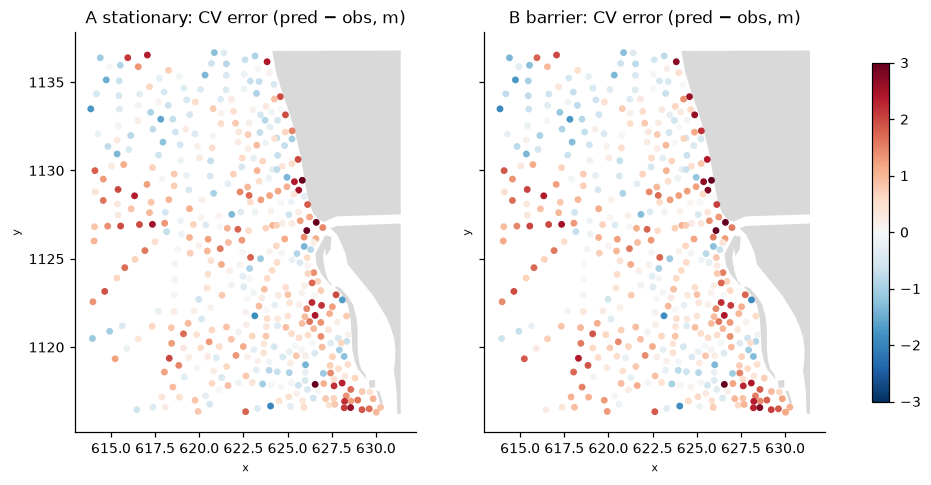

A stationary: correlation of CV errors between soundings < 800 m apart = 0.35
B barrier: correlation of CV errors between soundings < 800 m apart = 0.38


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, (m, d) in zip(axes, cv.groupby("model")):
    gpd.GeoSeries([land]).plot(ax=ax, color="0.85")
    v = 3
    sc = ax.scatter(d.x_km, d.y_km, c=d.err, cmap="RdBu_r", vmin=-v, vmax=v, s=12)
    ax.set_aspect("equal"); ax.set_title(f"{m}: CV error (pred − obs, m)")
plt.colorbar(sc, ax=axes, shrink=.8); plt.show()

from scipy.spatial import cKDTree
for m, d in cv.groupby("model"):
    t = cKDTree(d[["x_km", "y_km"]]); pairs = t.query_pairs(0.8, output_type="ndarray")
    r = np.corrcoef(d.err.values[pairs[:, 0]], d.err.values[pairs[:, 1]])[0, 1]
    print(f"{m}: correlation of CV errors between soundings < 800 m apart = {r:.2f}")

### Sensitivity to the mesh and the barrier range fraction

The barrier model has two choices that are not learnt from data: the mesh
resolution, and the fraction $r$ of the range allowed on land. Below, the model is
refitted with a coarser (500 m) and a finer (250 m) mesh, and with $r = 0.05$ and
$r = 0.2$. The quantity tracked is the posterior mean depth at three points that
matter for navigation: the mouth itself, the inner channel behind the long spit,
and a point on the open approach.

In [17]:
probe = pd.DataFrame({"name": ["mouth", "inner channel", "approach"],
                      "win_x": [1085, 1180, 800], "win_y": [815, 1300, 815]})
probe["x_km"], probe["y_km"] = win_to_km(probe.win_x, probe.win_y)
probe["dist_km"] = [coast.distance(Point(a, b)) for a, b in zip(probe.x_km, probe.y_km)]
probe.to_csv(PILOT / "probe.csv", index=False)
probe

,name,win_x,win_y,x_km,y_km,dist_km
0,mouth,1085,815,626.997145,1126.915394,0.191444
1,inner channel,1180,1300,628.176126,1121.051528,0.425865
2,approach,800,815,623.523682,1126.903125,2.974381


In [18]:
%%R -o sens
probe <- read.csv(paste0(D, "probe.csv"))
predict_at <- function(fit, mesh, pts) {
  A <- fm_basis(mesh, loc = as.matrix(pts[, c("x_km", "y_km")]))
  smp <- inla.posterior.sample(200, fit, selection = list(field = 1:mesh$n, b0 = 1, dist = 1), add.names = FALSE)
  m <- sapply(smp, function(z) { l <- z$latent[, 1]; as.vector(A %*% l[1:mesh$n]) + l[mesh$n + 1] + l[mesh$n + 2] * pts$dist_km })
  data.frame(name = pts$name, mean = rowMeans(m), sd = apply(m, 1, sd))
}
sens <- NULL
for (cfg in list(list(e = 0.5, r = 0.1), list(e = 0.35, r = 0.1), list(e = 0.25, r = 0.1),
                 list(e = 0.35, r = 0.05), list(e = 0.35, r = 0.2))) {
  m <- make_mesh(cfg$e); bt <- barrier_triangles(m)
  t0 <- Sys.time()
  fB <- if (cfg$e == 0.35 && cfg$r == 0.1) fitB else fit_model(m, bt, TRUE, range_fraction = cfg$r)
  secs <- as.numeric(Sys.time() - t0, units = "secs")
  p <- predict_at(fB, m, probe)
  sens <- rbind(sens, data.frame(max_edge_km = cfg$e, range_fraction = cfg$r, nodes = m$n, fit_s = round(secs, 1),
                                 mlik = fB$mlik[1], p))
}
if (TRUE) { pA <- predict_at(fitA, mesh, probe)
  sens <- rbind(sens, data.frame(max_edge_km = 0.35, range_fraction = NA, nodes = mesh$n, fit_s = NA, mlik = fitA$mlik[1], pA)) }

In [19]:
sens["model"] = np.where(sens.range_fraction.isna(), "A stationary", "B barrier")
sens["range_fraction"] = sens.range_fraction.fillna(1.0)       # the stationary model is the case r = 1
piv = sens.pivot_table(index=["model", "max_edge_km", "range_fraction", "nodes"], columns="name", values=["mean", "sd"])
print(piv.round(2).to_string())

                                                  mean                           sd                    
name                                          approach inner channel mouth approach inner channel mouth
model        max_edge_km range_fraction nodes                                                          
A stationary 0.35        1.00           7810      7.94          1.54  1.80     0.32          0.31  0.36
B barrier    0.25        0.10           15117     7.91          1.47  1.55     0.33          0.37  0.45
             0.35        0.05           7810      7.90          1.43  1.51     0.34          0.34  0.47
                         0.10           7810      7.96          1.43  1.56     0.35          0.34  0.47
                         0.20           7810      7.91          1.42  1.55     0.33          0.32  0.45
             0.50        0.10           3989      7.97          1.44  1.61     0.31          0.34  0.48


The barrier-model probe depths move by about 0.1 m across mesh resolutions from 250
to 500 m and range fractions from 0.05 to 0.2, which is well inside their posterior
sd. So the reconstruction is not an artefact of either choice. The one place the two
models differ is the mouth. There the barrier model is about 0.15 m shallower, with a posterior sd of
0.44–0.50 m against 0.39 m, because it stops the mouth from borrowing depth across the
spit from the backwater side.

## 8. Bathymetric reconstruction

Posterior surfaces are built from 300 joint samples of
$(\beta_0, \beta_1, u)$, projected onto the 150 m grid. Because the samples are joint,
each one is a complete, internally consistent seabed that fits the soundings. The
mean and sd maps summarise them, and the navigability section uses them
directly.

In [20]:
%%R -o nA -o nB
wet <- grid$water == 1
Agrid <- fm_basis(mesh, loc = as.matrix(grid[wet, c("x_km", "y_km")]))
dist_g <- grid$dist_km[wet]
draw <- function(fit, n = 300) {
  smp <- inla.posterior.sample(n, fit, selection = list(field = 1:mesh$n, b0 = 1, dist = 1), add.names = FALSE)
  sapply(smp, function(z) { l <- z$latent[, 1]; as.vector(Agrid %*% l[1:mesh$n]) + l[mesh$n + 1] + l[mesh$n + 2] * dist_g })
}
t0 <- Sys.time()
SA <- draw(fitA); SB <- draw(fitB)
writeBin(as.vector(SA), paste0(D, "samples_A.bin"), size = 4)
writeBin(as.vector(SB), paste0(D, "samples_B.bin"), size = 4)
nA <- dim(SA); nB <- dim(SB)
cat(sprintf("posterior sampling: %.0f s\n", as.numeric(Sys.time() - t0, units = "secs")))

posterior sampling: 2 s


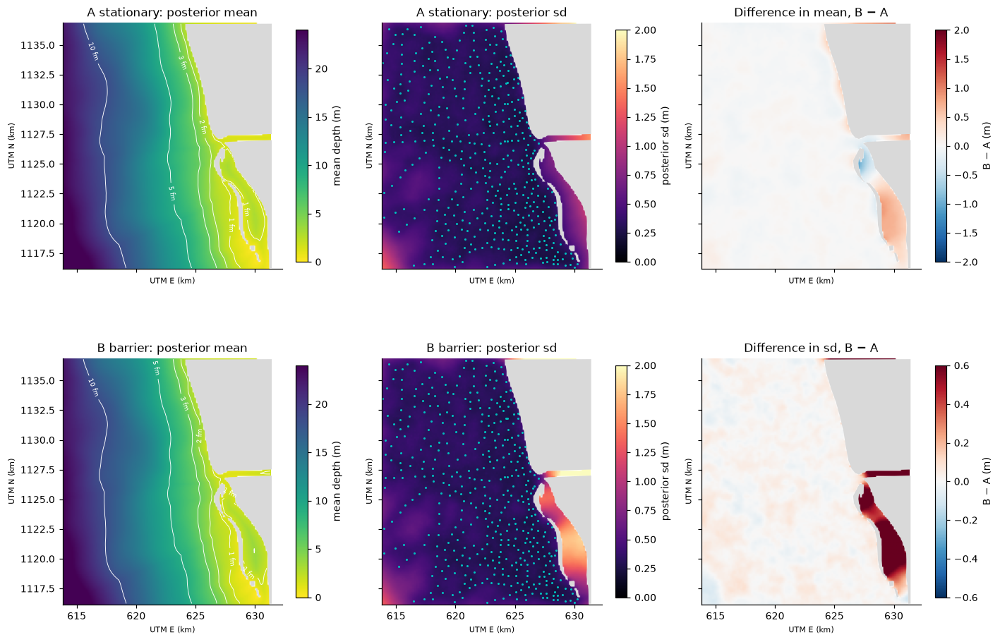

In [21]:
wet = grid.water.values
SA = np.fromfile(PILOT / "samples_A.bin", dtype=np.float32).reshape(tuple(np.asarray(nA, int)[::-1])).T
SB = np.fromfile(PILOT / "samples_B.bin", dtype=np.float32).reshape(tuple(np.asarray(nB, int)[::-1])).T
ny, nx = gx.shape

def to_img(v):
    out = np.full(grid.shape[0], np.nan); out[wet] = v; return out.reshape(ny, nx)

mean_A, sd_A = to_img(SA.mean(1)), to_img(SA.std(1))
mean_B, sd_B = to_img(SB.mean(1)), to_img(SB.std(1))
ext = [gx.min() - step/2, gx.max() + step/2, gy.min() - step/2, gy.max() + step/2]

fig, ax = plt.subplots(2, 3, figsize=(13, 9), sharex=True, sharey=True)
for row, (lab, m, sd) in enumerate([("A stationary", mean_A, sd_A), ("B barrier", mean_B, sd_B)]):
    im = ax[row, 0].imshow(m, origin="lower", extent=ext, cmap="viridis_r", vmin=0, vmax=24)
    cs = ax[row, 0].contour(gx, gy, m, levels=[1.83, 3.66, 5.49, 9.14, 18.3], colors="w", linewidths=.6)
    ax[row, 0].clabel(cs, fmt=lambda v: f"{v/FATHOM:.0f} fm", fontsize=6)
    plt.colorbar(im, ax=ax[row, 0], shrink=.7, label="mean depth (m)")
    im = ax[row, 1].imshow(sd, origin="lower", extent=ext, cmap="magma", vmin=0, vmax=2)
    ax[row, 1].scatter(s.x_km, s.y_km, s=1, c="c")
    plt.colorbar(im, ax=ax[row, 1], shrink=.7, label="posterior sd (m)")
    ax[row, 0].set_title(f"{lab}: posterior mean"); ax[row, 1].set_title(f"{lab}: posterior sd")
im = ax[0, 2].imshow(mean_B - mean_A, origin="lower", extent=ext, cmap="RdBu_r", vmin=-2, vmax=2)
plt.colorbar(im, ax=ax[0, 2], shrink=.7, label="B − A (m)"); ax[0, 2].set_title("Difference in mean, B − A")
im = ax[1, 2].imshow(sd_B - sd_A, origin="lower", extent=ext, cmap="RdBu_r", vmin=-.6, vmax=.6)
plt.colorbar(im, ax=ax[1, 2], shrink=.7, label="B − A (m)"); ax[1, 2].set_title("Difference in sd, B − A")
for a in ax.ravel():
    gpd.GeoSeries([land]).plot(ax=a, color="0.85", zorder=3); a.set_aspect("equal")
    a.set_xlabel("UTM E (km)"); a.set_ylabel("UTM N (km)")
plt.tight_layout(); fig.savefig(FIGS / "bathymetry_1857_maps.png", dpi=150); plt.show()

### Interactive 3D view

The surface is the barrier-model posterior mean, with vertical exaggeration.
Land is drawn as a flat plateau at +1 m. Black points are the 1857 soundings at
their recorded depth. The three faint surfaces are individual posterior samples,
which can be toggled in the legend. A second panel colours the mean surface by
posterior sd. The figure is also saved as a standalone HTML file in `figures/`.

In [22]:
X, Y = gx[0], gy[:, 0]
land_img = np.where(np.isnan(mean_B), 1.0, np.nan)
k = rng.choice(SB.shape[1], 3, replace=False)
fig = go.Figure()
fig.add_surface(x=X, y=Y, z=-mean_B, colorscale="Viridis", reversescale=True, cmin=-24, cmax=0,
                colorbar=dict(title="elevation (m)"), name="posterior mean", showlegend=True,
                contours=dict(z=dict(show=True, start=-22, end=0, size=1.8288, color="white", width=1)),
                hovertemplate="E %{x:.2f} km<br>N %{y:.2f} km<br>depth %{z:.1f} m<extra>mean</extra>")
for j, kk in enumerate(k):
    fig.add_surface(x=X, y=Y, z=-to_img(SB[:, kk]), showscale=False, opacity=.35, colorscale="Greys",
                    name=f"posterior sample {j+1}", showlegend=True, visible="legendonly", hoverinfo="skip")
fig.add_surface(x=X, y=Y, z=land_img, colorscale=[[0, "tan"], [1, "tan"]], showscale=False, name="land 1857",
                showlegend=True, hoverinfo="skip")
fig.add_scatter3d(x=s.x_km, y=s.y_km, z=-s.depth_m, mode="markers", marker=dict(size=2, color="black"),
                  name="1857 soundings", customdata=np.c_[s.id, s.depth_m / FATHOM],
                  hovertemplate="%{customdata[0]}: %{customdata[1]:.2f} fm (%{z:.1f} m)<extra></extra>")
fig.update_layout(height=650, scene=dict(aspectmode="manual", aspectratio=dict(x=1, y=1.15, z=.35),
                  xaxis_title="UTM E (km)", yaxis_title="UTM N (km)", zaxis_title="elevation (m)"),
                  title="Seabed at the Kodungallur mouth, 1851–53 survey (barrier model, posterior mean)",
                  legend=dict(x=0, y=1))
fig.write_html(FIGS / "bathymetry_1857_3d.html", include_plotlyjs="cdn")
fig.show()

fig2 = go.Figure(go.Surface(x=X, y=Y, z=-mean_B, surfacecolor=sd_B, colorscale="Magma", cmin=0, cmax=2,
                            colorbar=dict(title="posterior sd (m)")))
fig2.update_layout(height=550, title="Uncertainty draped on the mean surface",
                   scene=dict(aspectmode="manual", aspectratio=dict(x=1, y=1.15, z=.35)))
fig2.write_html(FIGS / "bathymetry_1857_3d_sd.html", include_plotlyjs="cdn")
fig2.show()

## 8b. A near-shore model of the mouth

**Why the shore looks wrong above.** The 3D view above shows a jagged, cliffed coast.
Part of that is drawing: the 150 m grid blanks land cells, which leaves
stair-steps. Part of it is the model, and that part matters more.

* **The intercept puts water on the beach.** The mean $\beta_0 + \beta_1 d$ has an
  intercept of about 2 m, so the model puts 2 m of water *at the shoreline*.
* **The data show a beach face, then a shelf.** Within 100–300 m of the charted
  coast the soundings are already about one fathom, and they deepen slowly
  afterwards. Depth drops 1.5–2 m within the first couple of hundred metres, then
  shelves at about 2 m/km. A Matérn field with a range of 10 km cannot produce
  that kink.
* **The CV saw it.** Both global models over-predict depth by 0.6–0.8 m within
  1 km of land (section 7).

**The fix: a local model of the mouth with three additions.**

1. **Shoreline anchors.** On Admiralty charts the coastline is the high-water
   line, so relative to the low-water-springs datum it sits at about −0.46 m (half
   the 0.91 m spring rise). Points every 50 m along every shore, the spits
   included, enter as a second Gaussian likelihood at that depth. Their sd is
   fixed at 1 m, not estimated. The digitised coast is good to about ±120 m, and on
   a beach face of roughly 10 m/km that is ±1.2 m of depth. Letting INLA estimate
   the anchor noise was tried, and it collapsed to zero and destabilised the fit.
2. **A beach-face term in the mean.**
   $\beta_0 + \beta_1 d + \beta_2\,(1 - e^{-d/L_0})$ with $L_0 = 100$ m. This lets
   depth step down across the beach face and then follow the shelf slope.
3. **A finer mesh at the coast.** The maximum edge is 120 m, the shoreline points
   are mesh vertices, and the range prior is set for a smaller domain:
   $P(\rho < 0.3\text{ km}) = 0.1$.

The domain is an 8 × 13 km box around the mouth and the whole sounded Pallipur channel.
Two areas of water that the chart draws but Selby did not sound are masked:
the lagoon behind the long spit, and the river channel east of the mouth. The model
would otherwise give them a confident open-coast depth that nothing supports.
Blocked CV (six blocks) compares the same model without anchors, with anchors,
and the barrier version with anchors.

In [23]:
# navigation routes in window pixels, used here and in section 9
routes_px = {"open approach": [(400, 815), (800, 815)],
             "bar crossing": [(930, 815), (1085, 815)],
             "Pallipur channel": [(1085, 830), (1030, 900), (1010, 1000), (1040, 1100), (1100, 1200), (1130, 1350)]}
lx0, ly0 = win_to_km(800, 1700); lx1, ly1 = win_to_km(1450, 600)
local = box(float(lx0), float(ly0), float(lx1), float(ly1))
land_l = land.intersection(local)
coast_l = land_l.boundary.difference(local.boundary.buffer(0.02))
sl = s[[local.contains(Point(a, b)) for a, b in zip(s.x_km, s.y_km)]].copy()
sl["dist_km"] = [coast_l.distance(Point(a, b)) for a, b in zip(sl.x_km, sl.y_km)]
shore = [coast_l.interpolate(t) for t in np.arange(0, coast_l.length, 0.05)]
shore = pd.DataFrame(dict(x_km=[p.x for p in shore], y_km=[p.y for p in shore]))

# water the chart draws but Selby did not sound: the lagoon behind the long spit (north of the
# sounded flats) and the river channel east of the mouth. The open-coast mean function is wrong
# for enclosed water, so these are shown as 'unsounded' rather than given an invented depth.
UNSOUNDED_PX = [
    [(1145, 1102), (1240, 1050), (1280, 1100), (1320, 1150), (1350, 1200), (1380, 1250), (1400, 1300),
     (1415, 1350), (1420, 1400), (1418, 1450), (1412, 1500), (1250, 1500), (1245, 1350), (1240, 1250),
     (1225, 1190), (1200, 1150), (1165, 1110)],
    [(1160, 770), (1460, 762), (1460, 812), (1160, 822)]]
unsounded = unary_union([Polygon(np.column_stack(win_to_km(*zip(*p)))) for p in UNSOUNDED_PX]).difference(land_l)
assert not any(unsounded.contains(Point(a, b)) for a, b in zip(sl.x_km, sl.y_km)), "a sounding falls in the unsounded mask"

LOC = PILOT / "local"; LOC.mkdir(exist_ok=True); LOC_DIR = str(LOC)
sl.to_csv(LOC / "soundings.csv", index=False); shore.to_csv(LOC / "shore.csv", index=False)
gpd.GeoSeries([land_l]).to_file(LOC / "land.geojson", driver="GeoJSON")
gpd.GeoSeries([local]).to_file(LOC / "domain.geojson", driver="GeoJSON")

# empirical profile: what the soundings say about the beach face
prof = sl.groupby(pd.cut(sl.dist_km, [0, .2, .4, .6, 1, 1.5, 2, 3, 5]), observed=True).depth_m.agg(["count", "median"])
print(f"{len(sl)} soundings, {len(shore)} shoreline anchors, {(sl.dist_km < 1).sum()} soundings within 1 km of land")
print(prof.round(2).T.to_string())

157 soundings, 1169 shoreline anchors, 46 soundings within 1 km of land
dist_km  (0.0, 0.2]  (0.2, 0.4]  (0.4, 0.6]  (0.6, 1.0]  (1.0, 1.5]  (1.5, 2.0]  (2.0, 3.0]  (3.0, 5.0]
count          7.00       11.00       10.00       18.00       22.00       17.00       35.00       34.00
median         0.91        2.29        2.06        2.51        2.51        2.74        5.49        7.54


/Users/vivek/Documents/Thesis/Code/.venv/lib/python3.13/site-packages/pyogrio/geopandas.py:948: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(
/Users/vivek/Documents/Thesis/Code/.venv/lib/python3.13/site-packages/pyogrio/geopandas.py:948: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(


In [24]:
# rendering vertices: 40 m grid in water, 150 m on land, and the shoreline itself every 25 m,
# so the triangulated surface follows the coast instead of stepping round grid cells
def grid_in(poly, step, inside=True):
    xs, ys = np.meshgrid(np.arange(local.bounds[0], local.bounds[2], step), np.arange(local.bounds[1], local.bounds[3], step))
    p = gpd.GeoSeries(gpd.points_from_xy(xs.ravel(), ys.ravel()))
    keep = p.within(poly).values if inside else ~p.within(poly.buffer(0.03)).values & p.within(local).values
    return np.c_[xs.ravel()[keep], ys.ravel()[keep]]

wpts = grid_in(land_l.buffer(0.03), 0.04, inside=False)
lpts = grid_in(land_l.buffer(-0.03), 0.15)
spts = np.array([[p.x, p.y] for p in (coast_l.interpolate(t) for t in np.arange(0, coast_l.length, 0.025))])
verts = pd.DataFrame(np.r_[wpts, spts, lpts], columns=["x_km", "y_km"])
verts["kind"] = ["water"] * len(wpts) + ["shore"] * len(spts) + ["land"] * len(lpts)
in_uns = gpd.GeoSeries(gpd.points_from_xy(verts.x_km, verts.y_km)).within(unsounded).values
verts.loc[in_uns & (verts.kind == "water"), "kind"] = "unsounded"
verts["dist_km"] = [coast_l.distance(Point(a, b)) if k == "water" else 0.0 for a, b, k in zip(verts.x_km, verts.y_km, verts.kind)]
verts.to_csv(LOC / "verts.csv", index=False)
print(verts.kind.value_counts().to_string())

kind
water        39067
unsounded     6231
shore         2338
land          1217


In [25]:
%%R -i LOC_DIR -o local_cv -o local_fixed -o local_hyper -o nV
L <- paste0(LOC_DIR, "/")
sl <- read.csv(paste0(L, "soundings.csv")); shore <- read.csv(paste0(L, "shore.csv")); verts <- read.csv(paste0(L, "verts.csv"))
land_l <- st_read(paste0(L, "land.geojson"), quiet = TRUE); st_crs(land_l) <- NA
dom_l  <- st_read(paste0(L, "domain.geojson"), quiet = TRUE); st_crs(dom_l) <- NA
# fine (150 m) in and near the water, coarse (600 m) over land, with shoreline points as vertices
water_l <- st_difference(st_geometry(dom_l), st_geometry(land_l))
inner_l <- st_intersection(st_buffer(water_l, 0.25), st_geometry(dom_l))
mesh_l <- fm_mesh_2d_inla(loc = as.matrix(shore[seq(1, nrow(shore), 2), 1:2]),
                          boundary = list(inner_l, st_buffer(st_geometry(dom_l), 0.5)), max.edge = c(0.15, 0.6), cutoff = 0.05)
cent <- st_centroid(fm_as_sfc(mesh_l)); st_crs(cent) <- NA
bar_l <- which(st_intersects(cent, land_l, sparse = FALSE)[, 1])
cat(mesh_l$n, "mesh nodes\n")
L0 <- 0.1; SHORE_DEPTH <- -0.46; SHORE_SD <- 1

fit_local <- function(barrier, anchors, y = sl$depth_m, mode = NULL) {
  spde <- if (barrier) suppressWarnings(inla.barrier.pcmatern(mesh_l, barrier.triangles = bar_l, prior.range = c(0.3, 0.1),
              prior.sigma = c(5, 0.1), range.fraction = 0.1, enable.INLAspacetime = FALSE)) else
          inla.spde2.pcmatern(mesh_l, prior.range = c(0.3, 0.1), prior.sigma = c(5, 0.1))
  stk <- inla.stack(data = list(Y = if (anchors) cbind(y, NA) else y), tag = "snd",
                    A = list(fm_basis(mesh_l, as.matrix(sl[, c("x_km", "y_km")])), 1),
                    effects = list(field = 1:mesh_l$n, data.frame(b0 = 1, dist = sl$dist_km, beach = 1 - exp(-sl$dist_km / L0))))
  fam <- "gaussian"; cf <- list(list(hyper = list(prec = list(prior = "pc.prec", param = c(0.5, 0.5)))))
  if (anchors) {
    n2 <- nrow(shore)
    stk <- inla.stack(stk, inla.stack(data = list(Y = cbind(rep(NA, n2), rep(SHORE_DEPTH, n2))), tag = "shore",
                      A = list(fm_basis(mesh_l, as.matrix(shore[, 1:2])), 1),
                      effects = list(field = 1:mesh_l$n, data.frame(b0 = rep(1, n2), dist = 0, beach = 0))))
    fam <- c("gaussian", "gaussian")
    cf <- c(cf, list(list(hyper = list(prec = list(initial = log(1 / SHORE_SD^2), fixed = TRUE)))))
  }
  suppressWarnings(inla(Y ~ 0 + b0 + dist + beach + f(field, model = spde), family = fam, data = inla.stack.data(stk),
       control.predictor = list(A = inla.stack.A(stk), compute = TRUE), control.family = cf,
       control.compute = list(config = TRUE), control.inla = list(int.strategy = "eb"),
       control.mode = if (is.null(mode)) list() else list(theta = mode, restart = TRUE)))
}

set.seed(1); sl$block <- kmeans(as.matrix(sl[, c("x_km", "y_km")]), centers = 6, nstart = 20)$cluster
local_cv <- NULL; local_fixed <- NULL; local_hyper <- NULL; fits <- list()
t0 <- Sys.time()
for (cfg in list(list("C stationary, no anchors", FALSE, FALSE), list("D stationary + anchors", FALSE, TRUE),
                 list("E barrier + anchors", TRUE, TRUE))) {
  f0 <- fit_local(cfg[[2]], cfg[[3]]); fits[[cfg[[1]]]] <- f0
  local_fixed <- rbind(local_fixed, data.frame(model = cfg[[1]], term = rownames(f0$summary.fixed), f0$summary.fixed[, c(1, 3, 5)]))
  local_hyper <- rbind(local_hyper, data.frame(model = cfg[[1]], noise_sd = 1 / sqrt(f0$summary.hyperpar[1, "mean"])))
  for (b in sort(unique(sl$block))) {
    y <- sl$depth_m; y[sl$block == b] <- NA
    f <- fit_local(cfg[[2]], cfg[[3]], y = y, mode = f0$mode$theta); i <- which(sl$block == b)
    lp <- f$summary.linear.predictor[i, ]
    local_cv <- rbind(local_cv, data.frame(model = cfg[[1]], id = sl$id[i], obs = sl$depth_m[i], dist_km = sl$dist_km[i],
                      mean = lp$mean, sd = sqrt(lp$sd^2 + 1 / f$summary.hyperpar[1, "mean"])))
  }
}
cat(sprintf("local fits and CV: %.0f s\n", as.numeric(Sys.time() - t0, units = "secs")))

# joint posterior samples of the anchored stationary model (D) at the rendering vertices
fD <- fits[["D stationary + anchors"]]
Av <- fm_basis(mesh_l, as.matrix(verts[, c("x_km", "y_km")]))
bv <- 1 - exp(-verts$dist_km / L0)
smp <- inla.posterior.sample(300, fD, selection = list(field = 1:mesh_l$n, b0 = 1, dist = 1, beach = 1), add.names = FALSE)
SV <- sapply(smp, function(z) { l <- z$latent[, 1]; n <- mesh_l$n
  as.vector(Av %*% l[1:n]) + l[n + 1] + l[n + 2] * verts$dist_km + l[n + 3] * bv })
writeBin(as.vector(SV), paste0(L, "samples_verts.bin"), size = 4); nV <- dim(SV)

10717

mesh nodes


local fits and CV: 124 s


In [26]:
z = (local_cv.obs - local_cv["mean"]) / local_cv["sd"]
local_cv["err"] = local_cv["mean"] - local_cv.obs
local_cv["in90"] = np.abs(z) < 1.645
local_cv["crps"] = local_cv["sd"] * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi))
tab_l = pd.concat({"all (local box)": local_cv.groupby("model").apply(scores, include_groups=False),
                   "within 1 km of land": local_cv[local_cv.dist_km < 1].groupby("model").apply(scores, include_groups=False)})
print(tab_l.round(2).to_string(), "\n")
print(local_fixed.round(2).to_string(index=False), "\n")
print(local_hyper.round(2).to_string(index=False))

                                                  n  RMSE   MAE  bias  cover90  CRPS
                    model                                                           
all (local box)     C stationary, no anchors  157.0  1.41  1.07  0.43     0.78  0.78
                    D stationary + anchors    157.0  1.33  1.09 -0.01     0.72  0.79
                    E barrier + anchors       157.0  1.64  1.36 -0.02     0.80  0.97
within 1 km of land C stationary, no anchors   46.0  1.95  1.57  0.76     0.67  1.14
                    D stationary + anchors     46.0  1.49  1.26 -0.17     0.63  0.92
                    E barrier + anchors        46.0  1.76  1.49 -0.32     0.76  1.06 

                   model  term  mean  X0.025quant  X0.975quant
C stationary, no anchors    b0  1.97        -1.28         5.23
C stationary, no anchors  dist  1.56         1.11         2.02
C stationary, no anchors beach -0.45        -3.84         2.95
  D stationary + anchors    b0 -0.41        -1.20         0.38
  D

**What changes.** With anchors and the beach-face term, the fitted profile is
physically sensible:

* the intercept sits at about −0.4 m, on the anchors;
* the beach face adds a step of about 2.3 m;
* the shelf then deepens at about 1.5 m/km.

The anchored stationary model (D) is the best near land on RMSE and bias. Its
intervals are still too narrow there: coverage is around 0.7, against a target of
0.9, so the near-shore sd is an under-statement of the real uncertainty. The barrier
version (E) needs a larger noise term, about 1.3 m, to fit and does no better. As in
the global model, the survey has no soundings behind the spits for it to use. Model
D is therefore used for the close-up and for the navigation figures below.

### Close-up in 3D

The surface is triangulated through the shoreline itself (vertices every 25 m along
the coast), so the coast is drawn where the chart draws it. Land is shown schematically
as a flat surface 2 m above datum, because the chart has no land heights. Depth
contours are at 1, 2, 3 and 5 fathoms. The two navigation routes from section 9
are drawn on the seabed. Two individual posterior samples can be switched on in the
legend to see how much the seabed could plausibly differ.

In [27]:
import matplotlib.tri as mtri
SV = np.fromfile(LOC / "samples_verts.bin", dtype=np.float32).reshape(tuple(np.asarray(nV, int)[::-1])).T
vx, vy, kind = verts.x_km.values, verts.y_km.values, verts.kind.values
wet_v = np.isin(kind, ["water", "shore"])
uns_v = kind == "unsounded"
elev_mean = np.where(wet_v, -SV.mean(1), np.where(uns_v, -0.3, 2.0))   # land drawn flat at +2 m, unsounded water flat at -0.3 m
elev_sd = np.where(wet_v, SV.std(1), np.nan)

tri = mtri.Triangulation(vx, vy)
t = tri.triangles
cx, cy = vx[t].mean(1), vy[t].mean(1)
cpts = gpd.GeoSeries(gpd.points_from_xy(cx, cy))
on_land = cpts.within(land_l).values
on_uns = cpts.within(unsounded).values
long_edge = np.max(np.hypot(np.diff(vx[t][:, [0, 1, 2, 0]], axis=1), np.diff(vy[t][:, [0, 1, 2, 0]], axis=1)), axis=1) > 0.25
water_tri, land_tri, uns_tri = t[~on_land & ~on_uns & ~long_edge], t[on_land], t[on_uns & ~long_edge]

def mesh_trace(tris, z, **kw):
    return go.Mesh3d(x=vx, y=vy, z=z, i=tris[:, 0], j=tris[:, 1], k=tris[:, 2], **kw)

fig = go.Figure()
fig.add_trace(mesh_trace(water_tri, elev_mean, intensity=elev_mean, colorscale="Viridis", cmin=-12, cmax=0.5,
              colorbar=dict(title="elevation<br>(m, datum)"), name="seabed, posterior mean", showlegend=True,
              hovertemplate="E %{x:.2f}<br>N %{y:.2f}<br>%{z:.1f} m<extra></extra>"))
fig.add_trace(mesh_trace(land_tri, np.full(len(vx), 2.0), color="tan", opacity=1, name="land (1857 chart)",
              showlegend=True, hoverinfo="skip"))
fig.add_trace(mesh_trace(uns_tri, np.full(len(vx), -0.3), color="lightsteelblue", opacity=1,
              name="water not sounded in 1851–53", showlegend=True, hoverinfo="skip"))
for j, kk in enumerate(rng.choice(SV.shape[1], 2, replace=False)):
    fig.add_trace(mesh_trace(water_tri, np.where(wet_v, -SV[:, kk], 0.0), color="lightgrey", opacity=.45,
                  name=f"posterior sample {j+1}", showlegend=True, visible="legendonly", hoverinfo="skip"))

# depth contours, traced on the mean surface
tri_w = mtri.Triangulation(vx, vy, water_tri)
cs = plt.figure().add_subplot().tricontour(tri_w, -elev_mean, levels=[1 * FATHOM, 2 * FATHOM, 3 * FATHOM, 5 * FATHOM]); plt.close()
for lev, segs in zip(cs.levels, cs.allsegs):
    xs, ys = [], []
    for seg in segs:
        xs += list(seg[:, 0]) + [None]; ys += list(seg[:, 1]) + [None]
    fig.add_scatter3d(x=xs, y=ys, z=[-lev + .05 if v is not None else None for v in xs], mode="lines",
                      line=dict(color="white", width=3), name=f"{lev / FATHOM:.0f} fm contour", hoverinfo="skip")

near = sl[(sl.x_km > local.bounds[0])]
fig.add_scatter3d(x=near.x_km, y=near.y_km, z=-near.depth_m, mode="markers", marker=dict(size=3, color="black"),
                  name="1857 soundings", customdata=np.c_[near.id, near.depth_m / FATHOM],
                  hovertemplate="%{customdata[0]}: %{customdata[1]:.2f} fm<extra></extra>")
vtree = cKDTree(np.c_[vx, vy])
for name in ["bar crossing", "Pallipur channel"]:
    line = LineString(np.column_stack(win_to_km(*zip(*routes_px[name]))))
    pts = np.array([[p.x, p.y] for p in (line.interpolate(u) for u in np.arange(0, line.length, 0.02))])
    _, i = vtree.query(pts)
    fig.add_scatter3d(x=pts[:, 0], y=pts[:, 1], z=elev_mean[i] + .1, mode="lines", line=dict(color="red", width=5), name=name)

fig.update_layout(height=700, title="Kodungallur mouth and Pallipur channel, 1851–53: near-shore model (D), posterior mean",
                  scene=dict(aspectmode="manual", aspectratio=dict(x=.75, y=1, z=.3), xaxis_title="UTM E (km)",
                             yaxis_title="UTM N (km)", zaxis_title="elevation (m)",
                             camera=dict(eye=dict(x=-1.4, y=-1.1, z=.9))),
                  legend=dict(x=0, y=1))
fig.write_html(FIGS / "mouth_1857_3d.html", include_plotlyjs="cdn")
fig.show()

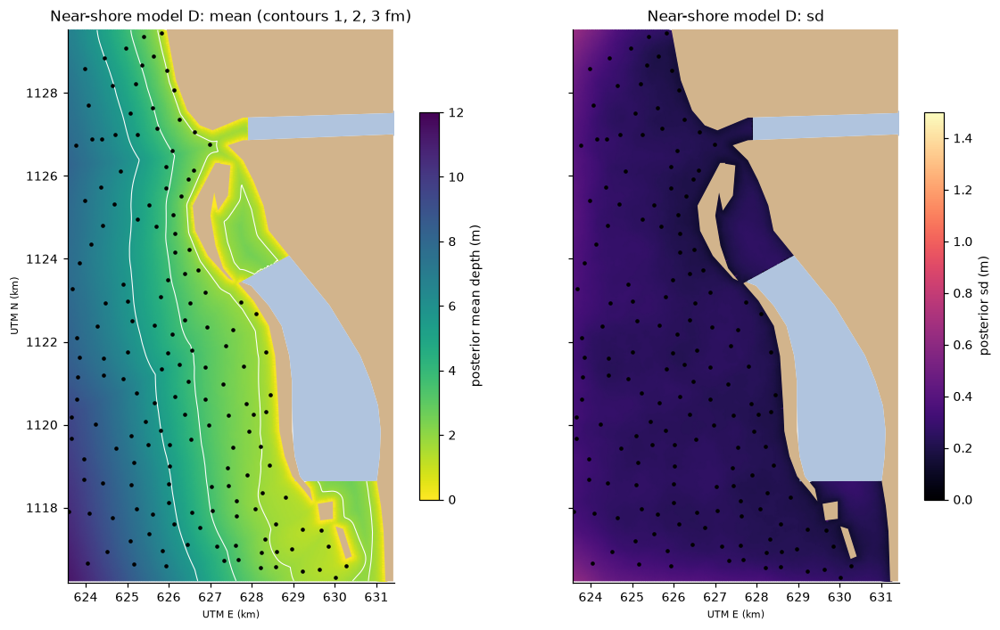

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(11, 6.5), sharey=True)
for a, val, cmap, lab, lim in [(ax[0], -elev_mean, "viridis_r", "posterior mean depth (m)", (0, 12)),
                               (ax[1], elev_sd, "magma", "posterior sd (m)", (0, 1.5))]:
    tc = a.tripcolor(tri_w, np.nan_to_num(val), cmap=cmap, vmin=lim[0], vmax=lim[1], shading="gouraud")
    gpd.GeoSeries([land_l]).plot(ax=a, color="tan", zorder=3)
    gpd.GeoSeries([unsounded]).plot(ax=a, color="lightsteelblue", zorder=3)
    a.scatter(sl.x_km, sl.y_km, s=4, c="k", zorder=4)
    plt.colorbar(tc, ax=a, shrink=.7, label=lab); a.set_aspect("equal"); a.set_xlabel("UTM E (km)")
    a.set_xlim(local.bounds[0], local.bounds[2]); a.set_ylim(local.bounds[1], local.bounds[3])
ax[0].tricontour(tri_w, -elev_mean, levels=[FATHOM, 2 * FATHOM, 3 * FATHOM], colors="w", linewidths=.7)
ax[0].set_ylabel("UTM N (km)"); ax[1].set_ylabel(""); ax[0].set_title("Near-shore model D: mean (contours 1, 2, 3 fm)"); ax[1].set_title("Near-shore model D: sd")
plt.tight_layout(); fig.savefig(FIGS / "mouth_1857_maps.png", dpi=150); plt.show()

## 9. Navigability

For a route $R$, the probability that the whole route is deeper than a ship needs is

$$P\Big(\min_{s\in R} D(s) > d_{\text{ship}} \,\Big|\, Y\Big),\qquad d_{\text{ship}} = \text{draught} + 0.5\text{ m clearance}.$$

Because the minimum is taken along each *joint* posterior sample, the shallowest
point of the route and its uncertainty are handled together. Taking the minimum
of the pointwise means would overstate the depth.

Three routes, drawn on the chart grid:

* **open approach**: 5 km of open water due west of the mouth, as a control;
* **bar crossing**: from 2 km offshore into the mouth, across the bar;
* **Pallipur channel**: from the mouth south along the sounded channel behind the
  long spit.

Depths are relative to the assumed datum, low water springs. At high water springs
add about 0.9 m.

**An independent check.** The Admiralty's *West Coast of Hindostan Pilot* (Taylor,
1866: 82), written from the same surveys, says of the Paliport river: "The river has
a bar, and is only available for small coasting craft." It also describes a soft mud
bank 5 miles south of the mouth "having little more than one fathom on it",
extending nearly 3 miles to seaward. The reconstruction should agree with that
description, and the table below is the test.

open approach: 4.88 km, 33 grid cells
bar crossing: 1.89 km, 13 grid cells
Pallipur channel: 6.84 km, 55 grid cells


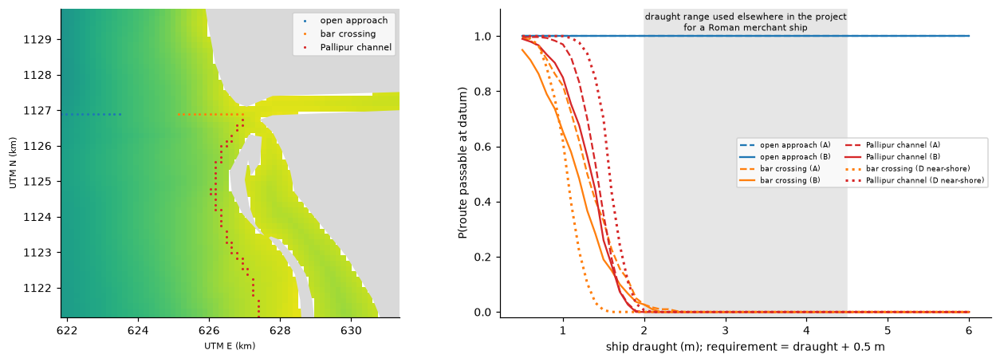

           route model  min_depth_mean  min_depth_5  min_depth_95  P(ok) draught 1.5 m  P(ok) draught 2.5 m  P(ok) draught 3.5 m  P(ok) draught 4.5 m
   open approach     A            8.01         7.49          8.55                 1.00                  1.0                  1.0                  1.0
   open approach     B            8.02         7.55          8.53                 1.00                  1.0                  1.0                  1.0
    bar crossing     A            1.82         1.23          2.39                 0.33                  0.0                  0.0                  0.0
    bar crossing     B            1.66         1.01          2.36                 0.19                  0.0                  0.0                  0.0
Pallipur channel     A            1.91         1.56          2.27                 0.35                  0.0                  0.0                  0.0
Pallipur channel     B            1.80         1.26          2.22                 0.26              

In [29]:
grid_xy = np.c_[grid.x_km[wet], grid.y_km[wet]]
tree = cKDTree(grid_xy)
route_idx = {}
for name, px in routes_px.items():
    line = LineString(np.column_stack(win_to_km(*zip(*px))))
    pts = [line.interpolate(t) for t in np.arange(0, line.length, 0.05)]
    d, i = tree.query([(p.x, p.y) for p in pts])
    route_idx[name] = np.unique(i[d < step])          # grid cells the route passes through
    print(f"{name}: {line.length:.2f} km, {len(route_idx[name])} grid cells")

draughts = np.arange(0.5, 6.01, 0.1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
gpd.GeoSeries([land]).plot(ax=ax[0], color="0.85")
ax[0].imshow(mean_B, origin="lower", extent=ext, cmap="viridis_r", vmin=0, vmax=24)
cols = dict(zip(routes_px, ["tab:blue", "tab:orange", "tab:red"]))
rows = []
for name, idx in route_idx.items():
    ax[0].plot(*grid_xy[idx].T, ".", ms=2, color=cols[name], label=name)
    for lab, S, ls in [("A", SA, "--"), ("B", SB, "-")]:
        mins = S[idx].min(0)
        p = (mins[None, :] > draughts[:, None] + 0.5).mean(1)
        ax[1].plot(draughts, p, ls, color=cols[name], label=f"{name} ({lab})")
        rows.append(dict(route=name, model=lab, min_depth_mean=mins.mean(), min_depth_5=np.percentile(mins, 5),
                         min_depth_95=np.percentile(mins, 95),
                         **{f"P(ok) draught {d} m": (mins > d + .5).mean() for d in [1.5, 2.5, 3.5, 4.5]}))
# the near-shore model D, on its own vertices (only routes inside the local box)
water_v = np.where(wet_v)[0]; vt = cKDTree(np.c_[vx[water_v], vy[water_v]])
for name in ["bar crossing", "Pallipur channel"]:
    line = LineString(np.column_stack(win_to_km(*zip(*routes_px[name]))))
    pts = [line.interpolate(u) for u in np.arange(0, line.length, 0.025)]
    d, i = vt.query([(p.x, p.y) for p in pts]); idx = np.unique(water_v[i[d < 0.05]])
    mins = SV[idx].min(0)
    p = (mins[None, :] > draughts[:, None] + 0.5).mean(1)
    ax[1].plot(draughts, p, ":", color=cols[name], lw=2, label=f"{name} (D near-shore)")
    rows.append(dict(route=name, model="D", min_depth_mean=mins.mean(), min_depth_5=np.percentile(mins, 5),
                     min_depth_95=np.percentile(mins, 95),
                     **{f"P(ok) draught {d} m": (mins > d + .5).mean() for d in [1.5, 2.5, 3.5, 4.5]}))
ax[0].set_xlim(ext[0] + 8, ext[1]); ax[0].set_ylim(ext[2] + 5, ext[3] - 7); ax[0].legend(fontsize=7); ax[0].set_aspect("equal")
ax[0].set_xlabel("UTM E (km)"); ax[0].set_ylabel("UTM N (km)")
ax[1].axvspan(2, 4.5, color="0.9", zorder=0)
ax[1].text(3.25, 1.02, "draught range used elsewhere in the project\nfor a Roman merchant ship", ha="center", fontsize=7)
ax[1].set_xlabel("ship draught (m); requirement = draught + 0.5 m"); ax[1].set_ylabel("P(route passable at datum)")
ax[1].legend(fontsize=6, ncol=2); ax[1].set_ylim(-.02, 1.1)
plt.tight_layout(); fig.savefig(FIGS / "navigability_1857.png", dpi=150); plt.show()
nav = pd.DataFrame(rows); print(nav.round(2).to_string(index=False))

**Result.** The open approach is passable at any plausible draught. The bar is not:
its shallowest point is about 1.7–1.8 m at low water springs (90% interval roughly
1.0–2.4 m), so even a 1.5 m-draught boat with 0.5 m clearance gets over at low water
in only about a quarter to a third of posterior samples. Nothing drawing 2.5 m or
more crosses at low water. Adding the 0.9 m spring rise, a boat drawing about 2 m
could cross at high water. That is the Pilot's "small coasting craft", reproduced
from the soundings alone.

These are statements about the seabed **as surveyed in 1851–53**, at the assumed
datum. They are not statements about the first century AD. The bar at a
monsoon-coast river mouth moves seasonally and over decades, and the shoreline here
has moved by kilometres since the Early Historic period. The probabilities say how
well the soundings pin down the 1850s bar, which is the baseline that any later
model of change will start from.

## 9b. The circa-1700 chart

The manuscript *Carte particulière des costes de Canara et de Malabar, avec les
sondes* (BnF, Gallica btv1b53257153h) has eleven soundings between the Kodungallur
and Cochin mouths, transcribed earlier in the project from a crop of the sheet
(`data/raw/soundings_dutch_c1700.csv`). The chart has north to the left and no
usable graticule at this scale, so it is georeferenced by a similarity transform
(rotation, scale, shift) from two control points:

* the Kodungallur mouth, crop pixel (195, 705), placed at the mouth on sheet 749;
* the Cochin (Vypin) mouth, crop pixel (505, 560), placed at the modern inlet, 9.967 N 76.242 E.

Two points determine a similarity exactly, so there is no residual to check it
against. Positions between the control points are probably good to a kilometre or
two; that is a guess based on the chart's scale and style, not a measurement. Eleven
soundings cannot support estimating a spatial field, so the model reuses the 1857
posterior: the same mean function and a stationary Matérn field with range and sd
fixed at the 1857 Model A estimates, fitted with intercept and slope free. Distance
offshore is measured to the Natural Earth 10 m coastline, because the c.1700 coast
has not been digitised.

In [30]:
d17 = pd.read_csv(ROOT / "data/raw/soundings_dutch_c1700.csv")
d17 = d17[d17.place == "Cranganore"].copy()
mouth_kod = np.array(win_to_km(1100, 815)) * 1000
mouth_coc = np.array(to_utm.transform(76.242, 9.967))
z_crop = np.array([195 - 705j, 505 - 560j])                   # flip y so the transform is a rotation
z_utm = np.array([complex(*mouth_kod), complex(*mouth_coc)])
a = (z_utm[1] - z_utm[0]) / (z_crop[1] - z_crop[0]); b = z_utm[0] - a * z_crop[0]
w = a * (d17.crop_x.values - 1j * d17.crop_y.values) + b
d17["x_km"], d17["y_km"] = w.real / 1000, w.imag / 1000
d17["depth_m"] = d17.fathoms * FATHOM
print(f"implied chart scale: 1 crop px = {abs(a):.0f} m, rotation {np.degrees(np.angle(a)):.0f}°")

ne = gpd.read_file(ROOT / "data/raw/ne10m/ne_10m_coastline.shp").cx[75.9:76.5, 9.7:10.5].to_crs(32643)
ne_line = unary_union(ne.geometry)
d17["dist_km"] = [ne_line.distance(Point(x * 1000, y * 1000)) / 1000 for x, y in zip(d17.x_km, d17.y_km)]
d17[["fathoms", "setting", "note", "x_km", "y_km", "dist_km"]].round(2)

implied chart scale: 1 crop px = 77 m, rotation -95°


,fathoms,setting,note,x_km,y_km,dist_km
0,3.0,entrance,beside a drawn shoal bank at the Vypin entrance,630.96,1098.07,5.05
1,4.5,entrance,in the channel between shoals,627.80,1093.24,8.90
2,5.0,entrance,NaN,623.83,1099.04,11.78
3,5.0,approach,NaN,621.66,1126.03,5.95
4,6.0,approach,NaN,621.14,1122.04,7.92
5,7.0,approach,NaN,620.80,1116.63,8.78
6,8.0,approach,NaN,621.08,1094.48,15.37
7,9.0,approach,NaN,617.06,1103.93,16.55
8,10.0,approach,NaN,619.98,1109.49,11.79
9,11.0,approach,NaN,616.71,1135.41,7.57


In [31]:
r_fix = float(hyper_tab.loc[hyper_tab.model == "A stationary", "range_km"].iloc[0])
s_fix = float(hyper_tab.loc[hyper_tab.model == "A stationary", "field_sd_m"].iloc[0])
d17.to_csv(PILOT / "soundings_c1700.csv", index=False)

In [32]:
%%R -i r_fix -i s_fix -o fix17 -o loo17
d17 <- read.csv(paste0(D, "soundings_c1700.csv"))
bnd <- fm_nonconvex_hull(as.matrix(d17[, c("x_km", "y_km")]), convex = 3)
m17 <- fm_mesh_2d_inla(boundary = bnd, max.edge = c(0.5, 3), offset = c(1, 5), cutoff = 0.2)
spde17 <- inla.spde2.pcmatern(m17, prior.range = c(r_fix, NA), prior.sigma = c(s_fix, NA))  # fixed at 1857 values
A17 <- fm_basis(m17, loc = as.matrix(d17[, c("x_km", "y_km")]))
fit17 <- function(y) inla(y ~ 0 + b0 + dist + f(field, model = spde17),
          data = inla.stack.data(stk <- inla.stack(data = list(y = y), A = list(A17, 1),
                 effects = list(field = 1:m17$n, data.frame(b0 = 1, dist = d17$dist_km)))),
          control.predictor = list(A = inla.stack.A(stk), compute = TRUE),
          control.family = list(hyper = list(prec = list(prior = "pc.prec", param = c(0.5, 0.5)))))
f <- fit17(d17$depth_m)
fix17 <- cbind(term = rownames(f$summary.fixed), f$summary.fixed[, c(1, 2, 3, 5)])
loo17 <- NULL
for (i in seq_len(nrow(d17))) { y <- d17$depth_m; y[i] <- NA; fi <- fit17(y)
  loo17 <- rbind(loo17, data.frame(i = i, obs = d17$depth_m[i], mean = fi$summary.linear.predictor[i, "mean"],
                                   sd = sqrt(fi$summary.linear.predictor[i, "sd"]^2 + 1 / fi$summary.hyperpar[1, "mean"]))) }

In [33]:
print("c.1700 model, fixed effects (compare the 1857 slope of ~1.7 m/km):")
print(fix17.round(2).to_string(index=False))
loo17["err"] = loo17["mean"] - loo17.obs
print(f"\nleave-one-out over 11 soundings: RMSE {np.sqrt((loo17.err**2).mean()):.2f} m, "
      f"90% coverage {(np.abs(loo17.err / loo17['sd']) < 1.645).mean():.2f}")

# where the two surveys overlap: 1857 posterior at the c.1700 positions inside the 1857 domain
inside = [domain.contains(Point(x, y)) and not land.contains(Point(x, y)) for x, y in zip(d17.x_km, d17.y_km)]
o = d17[inside]
if len(o):
    _, gi = tree.query(o[["x_km", "y_km"]])
    o = o.assign(depth_1857_mean=SB[gi].mean(1), depth_1857_sd=SB[gi].std(1))
    print("\nc.1700 soundings that fall inside the 1857 domain, against the 1857 barrier posterior:")
    print(o[["fathoms", "depth_m", "depth_1857_mean", "depth_1857_sd", "note"]].round(2).to_string(index=False))

c.1700 model, fixed effects (compare the 1857 slope of ~1.7 m/km):
term  mean   sd  0.025quant  0.975quant
  b0  8.02 3.58        0.95       15.19
dist  0.57 0.34       -0.12        1.24

leave-one-out over 11 soundings: RMSE 4.66 m, 90% coverage 0.82

c.1700 soundings that fall inside the 1857 domain, against the 1857 barrier posterior:
 fathoms  depth_m  depth_1857_mean  depth_1857_sd note
     5.0     9.14            10.92           0.28  NaN
     6.0    10.97            12.07           0.36  NaN
     7.0    12.80            15.41           0.39  NaN
    11.0    20.12            16.92           0.38  NaN


**Result.** The c.1700 soundings do **not** follow the 1857 relation between depth
and distance offshore: the fitted slope is about 0.6 m/km against 1.7 m/km. Leave-one-out
prediction is poor (RMSE about 4.7 m). Where the two surveys overlap, the c.1700
depths differ from the 1857 posterior by −2.6 to +3.2 m, with no consistent sign.

That pattern is what positional error looks like. Moving a sounding a few kilometres
along a slope of 1.7 m/km changes its expected depth by several metres. So the
comparison mixes three unknowns: an unknown datum, a positional error of
kilometres, and real change over 150 years. A difference at any one point cannot be
assigned to any one of them.

The conclusion is narrow but useful. As georeferenced here, the c.1700 chart
supports statements about depth *ranges at named places*, which is how
`soundings_error.py` already uses it. It does not support a spatial model. To get
more from it, it needs a proper control-point georeference, using several coastal
features, before any modelling.

## 10. Discussion and limitations

**What the reconstruction is.** A probabilistic surface for the seabed at the
Kodungallur mouth as Selby's survey recorded it in 1851–53, built from 428
hand-transcribed soundings. It comes with an uncertainty that the blocked
cross-validation checks, and with joint posterior samples that can be pushed
through any downstream calculation, such as minimum depth on a route, area above a
draught, or volume of the bar.

**Stationary against barrier.** The data do not choose the barrier model. The
marginal likelihood and the blocked CV both slightly prefer the stationary model,
and on the open shelf the two are indistinguishable. That is a finding about the
survey, not about the coast: Selby did not sound behind the spits, so there are no
data for a barrier to separate. Where the models differ, at the mouth, the barrier
model is shallower by about 0.2 m and more uncertain, and it is the more cautious of
the two for navigation. The navigability conclusion, that the bar was for small craft
only, holds under both.

**Assumptions to keep in view.**

1. **Datum.** Assumed to be low water springs. If it is mean low water or another
   level, every depth shifts by up to about 0.9 m together. This does not change
   the shape of the seabed, but it does change the navigability probabilities.
2. **Edition.** The scan is the 1914 edition. Any soundings updated between 1857 and
   1914 would be mixed into "1851–53" without our knowing.
3. **Transcription.** It was read by eye and checked once against the chart crops.
   Twenty-five readings are flagged `unsure`, mostly lone fractions on the inner
   flats. They are included. A sensitivity run without them is a one-line change
   (`status == "ok"`).
4. **Barriers.** They were digitised by hand to about 120 m, and the backwaters are
   treated as land. Neither choice affects the open approach. Both affect the inner
   channel.
5. **Hyperparameter uncertainty.** INLA's empirical-Bayes mode fixes the
   hyperparameters at their posterior mode. Integrating over them
   (`int.strategy = "ccd"`) would widen the intervals slightly and roughly
   double the run time.
6. **Barrier implementation.** It uses INLA's `rgeneric` version of Bakka et al.
   (2019), because the compiled INLAspacetime version needs a newer INLA than R 4.5
   allows. The model is the same; only the speed differs.

**What comes next.** Extending the window north and south along sheet 749, so
that the Cochin mouth and the c.1700 soundings overlap properly. Finding larger-scale
surveys of the mouth, such as Admiralty chart 65, "Cochin and Alipee", whose scan has
not yet been located. Only after that does the step to Roman-period conditions
begin, which needs sea level and sediment, and is deliberately absent here.

**References.** Bakka, H. et al. (2019) "Non-stationary Gaussian models with
physical barriers", *Spatial Statistics* 29: 268–288. Lindgren, F., Rue, H. and
Lindström, J. (2011) "An explicit link between Gaussian fields and Gaussian Markov
random fields: the SPDE approach", *JRSS B* 73: 423–498. Rue, H., Martino, S. and
Chopin, N. (2009) "Approximate Bayesian inference for latent Gaussian models using
INLA", *JRSS B* 71: 319–392.